**AUTHOR:** OLASUNKANMI ADISA
**PROJECT:** UK Care Service Performance Analysis
**DATASET PERIOD:** Jan 2025 - Dec 2025

**1. DATA OVERVIEW**

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("uk_care_service_performance_synthetic.csv")

print("Dataset size:", df.shape)
display(df.head())

Dataset size: (1000, 15)


,record_id,service_date,month,service_location,service_users_supported,scheduled_visits,completed_visits,missed_visits,delayed_visits,staff_scheduled_hours,staff_absence_hours,staff_worked_hours,staff_attendance_rate_pct,incident_reports,service_user_satisfaction_score
0,CSR0001,2025-01-02,2025-01,Northampton Central,57,83,82,1,4,181.261759,4.7,176.6,97.4,0,4.6
1,CSR0002,2025-01-02,2025-01,Northampton East,53,80,76,4,7,156.985035,6.5,150.5,95.9,2,4.1
2,CSR0003,2025-01-02,2025-01,Northampton West,27,25,23,2,1,149.782126,20.7,129.1,86.2,0,4.2
3,CSR0004,2025-01-02,2025-01,Wellingborough,50,75,72,3,8,183.713129,2.5,181.2,98.6,0,4.6
4,CSR0005,2025-01-02,2025-01,Kettering,38,68,68,0,1,168.681603,5.6,163.1,96.7,0,4.8


**2. DATA QUALITY**

In [3]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

Missing values:
record_id                           0
service_date                        0
month                               0
service_location                    0
service_users_supported             0
scheduled_visits                    0
completed_visits                    0
missed_visits                       0
delayed_visits                      0
staff_scheduled_hours               0
staff_absence_hours                 0
staff_worked_hours                  0
staff_attendance_rate_pct           0
incident_reports                    0
service_user_satisfaction_score    24
dtype: int64

Duplicate records: 0


**3. OVERALL PERFORMANCE**

In [4]:
missed_rate = (
    df["missed_visits"].sum() /
    df["scheduled_visits"].sum() * 100
)

delayed_rate = (
    df["delayed_visits"].sum() /
    df["completed_visits"].sum() * 100
)

attendance_rate = (
    df["staff_worked_hours"].sum() /
    df["staff_scheduled_hours"].sum() * 100
)

incidents = df["incident_reports"].sum()

satisfaction = df["service_user_satisfaction_score"].mean()

kpis = pd.DataFrame({
    "KPI": [
        "Missed Visit Rate",
        "Delayed Visit Rate",
        "Staff Attendance Rate",
        "Total Incident Reports",
        "Average Satisfaction"
    ],
    "Result": [
        f"{missed_rate:.2f}%",
        f"{delayed_rate:.2f}%",
        f"{attendance_rate:.2f}%",
        f"{incidents:,}",
        f"{satisfaction:.3f} / 5"
    ]
})

display(kpis)

,KPI,Result
0,Missed Visit Rate,2.62%
1,Delayed Visit Rate,6.53%
2,Staff Attendance Rate,96.87%
3,Total Incident Reports,870
4,Average Satisfaction,4.399 / 5


**4. LOCATION PERFORMANCE**

In [5]:
location_summary = df.groupby("service_location").agg(
    scheduled=("scheduled_visits", "sum"),
    missed=("missed_visits", "sum"),
    completed=("completed_visits", "sum"),
    delayed=("delayed_visits", "sum")
)

location_summary["Missed Rate (%)"] = (
    location_summary["missed"] /
    location_summary["scheduled"] * 100
).round(2)

location_summary["Delayed Rate (%)"] = (
    location_summary["delayed"] /
    location_summary["completed"] * 100
).round(2)

display(
    location_summary[
        ["Missed Rate (%)", "Delayed Rate (%)"]
    ].sort_values("Missed Rate (%)", ascending=False)
)

,Missed Rate (%),Delayed Rate (%)
service_location,,
Northampton Central,3.12,6.66
Milton Keynes North,3.02,6.92
Corby,2.93,5.97
Wellingborough,2.80,7.20
Northampton East,2.59,6.29
Towcester,2.52,6.47
Daventry,2.44,6.07
Milton Keynes South,2.44,6.73
Northampton West,2.27,6.55


**5. MONTHLY TRENDS**

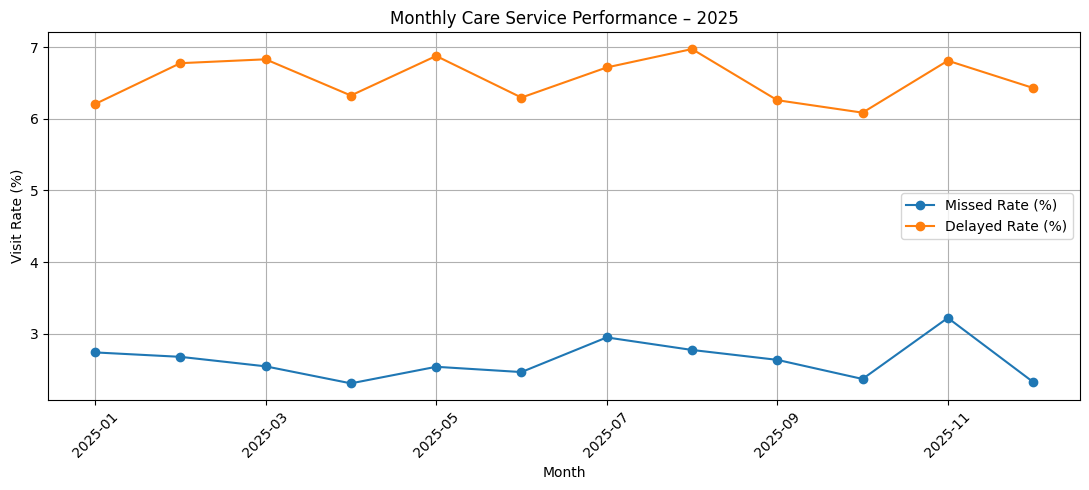

In [6]:
df["service_date"] = pd.to_datetime(df["service_date"])
df["month"] = df["service_date"].dt.to_period("M").astype(str)

monthly = df.groupby("month").agg(
    scheduled=("scheduled_visits", "sum"),
    missed=("missed_visits", "sum"),
    completed=("completed_visits", "sum"),
    delayed=("delayed_visits", "sum")
)

monthly["Missed Rate (%)"] = (
    monthly["missed"] / monthly["scheduled"] * 100
)

monthly["Delayed Rate (%)"] = (
    monthly["delayed"] / monthly["completed"] * 100
)

monthly[
    ["Missed Rate (%)", "Delayed Rate (%)"]
].plot(
    kind="line",
    marker="o",
    figsize=(11, 5),
    title="Monthly Care Service Performance – 2025"
)

plt.ylabel("Visit Rate (%)")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**6. PRIORITY LOCATION ANALYSIS**

In [7]:
priority = location_summary[
    (location_summary["Missed Rate (%)"] > missed_rate) &
    (location_summary["Delayed Rate (%)"] > delayed_rate)
].copy()

display(
    priority[
        ["Missed Rate (%)", "Delayed Rate (%)"]
    ]
)

,Missed Rate (%),Delayed Rate (%)
service_location,,
Milton Keynes North,3.02,6.92
Northampton Central,3.12,6.66
Wellingborough,2.80,7.20


**7. PRIORITY LOCATION VISUALISATION**

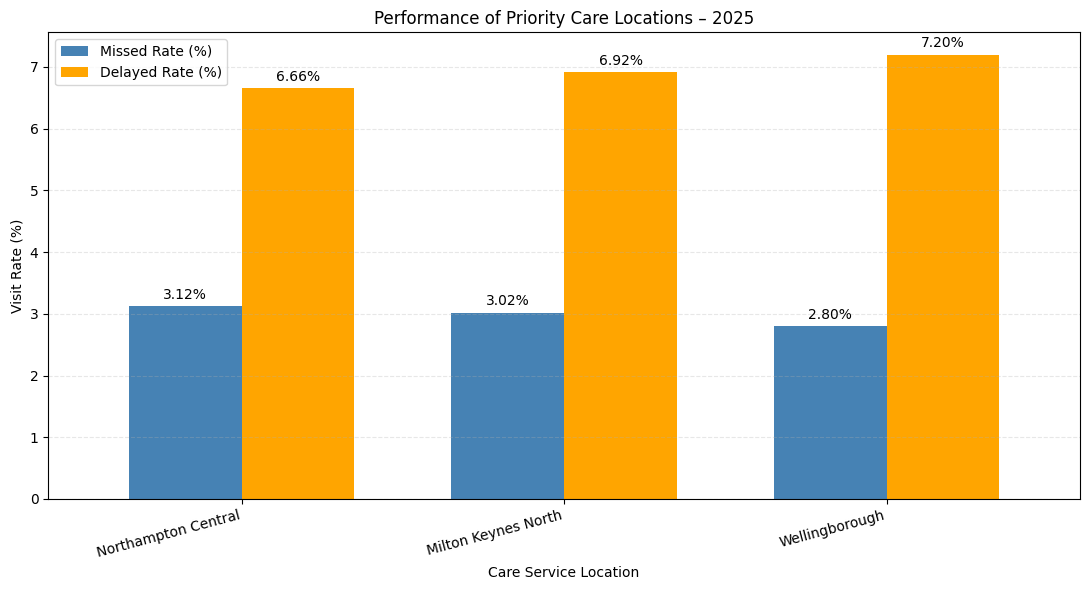

In [8]:
chart_data = priority[
    ["Missed Rate (%)", "Delayed Rate (%)"]
].sort_values("Missed Rate (%)", ascending=False)

ax = chart_data.plot(
    kind="bar",
    figsize=(11, 6),
    color=["steelblue", "orange"],
    width=0.7
)

plt.title("Performance of Priority Care Locations – 2025")
plt.xlabel("Care Service Location")
plt.ylabel("Visit Rate (%)")
plt.xticks(rotation=15, ha="right")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

**8. DATA QUALITY AUDIT REPORT**

In [9]:
import os

print(os.listdir('/content'))

['.config', 'uk_care_service_performance_synthetic.csv', 'sample_data']


In [10]:
from google.colab import files

uploaded = files.upload()

Saving uk_care_service_performance_synthetic.csv to uk_care_service_performance_synthetic (1).csv


In [11]:
import pandas as pd

filename = list(uploaded.keys())[0]

audit_df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Rows:", audit_df.shape[0])
print("Columns:", audit_df.shape[1])

Dataset loaded successfully!
Rows: 1000
Columns: 15


In [12]:

# LESSON 8: FINAL DATA QUALITY AUDIT REPORT

import pandas as pd
import numpy as np

# Work with a fresh copy of the original dataset

numeric_columns = [
    "service_users_supported",
    "scheduled_visits",
    "completed_visits",
    "missed_visits",
    "delayed_visits",
    "staff_scheduled_hours",
    "staff_absence_hours",
    "staff_worked_hours",
    "staff_attendance_rate_pct",
    "incident_reports",
    "service_user_satisfaction_score"
]

# Convert numeric columns safely
for col in numeric_columns:
    audit_df[col] = pd.to_numeric(
        audit_df[col], errors="coerce"
    )

dates = pd.to_datetime(
    audit_df["service_date"], errors="coerce"
)

# Check attendance calculations
expected_attendance = (
    audit_df["staff_worked_hours"] /
    audit_df["staff_scheduled_hours"].replace(0, np.nan)
) * 100

checks = {
    "Duplicate rows":
        int(audit_df.duplicated().sum()),

    "Duplicate record IDs":
        int(audit_df["record_id"].duplicated().sum()),

    "Missing record IDs":
        int(audit_df["record_id"].isna().sum()),

    "Missing satisfaction scores":
        int(audit_df["service_user_satisfaction_score"].isna().sum()),

    "Invalid or missing dates":
        int(dates.isna().sum()),

    "Dates outside 2025":
        int((dates.notna() & (dates.dt.year != 2025)).sum()),

    "Negative operational values":
        int((audit_df[
            [c for c in numeric_columns
             if c not in [
                 "service_user_satisfaction_score",
                 "staff_attendance_rate_pct"
             ]]
        ] < 0).sum().sum()),

    "Invalid satisfaction scores":
        int((
            (audit_df["service_user_satisfaction_score"] < 1) |
            (audit_df["service_user_satisfaction_score"] > 5)
        ).sum()),

    "Visit consistency failures":
        int((
            audit_df["scheduled_visits"] !=
            audit_df["completed_visits"] +
            audit_df["missed_visits"]
        ).sum()),

    "Staff hours consistency failures":
        int((~np.isclose(
            audit_df["staff_scheduled_hours"],
            audit_df["staff_worked_hours"] +
            audit_df["staff_absence_hours"],
            atol=0.01
        )).sum()),

    "Attendance calculation failures":
        int((~np.isclose(
            expected_attendance,
            audit_df["staff_attendance_rate_pct"],
            atol=0.1,
            equal_nan=False
        )).sum())
}

audit_report = pd.DataFrame(
    list(checks.items()),
    columns=["Quality Check", "Records Flagged"]
)

display(audit_report)

print("\nTotal records:", len(audit_df))
print("Total columns:", audit_df.shape[1])
print("Unique locations:",
      audit_df["service_location"].nunique())
print("Months covered:",
      dates.dt.to_period("M").nunique())


,Quality Check,Records Flagged
0,Duplicate rows,0
1,Duplicate record IDs,0
2,Missing record IDs,0
3,Missing satisfaction scores,24
4,Invalid or missing dates,0
5,Dates outside 2025,0
6,Negative operational values,0
7,Invalid satisfaction scores,0
8,Visit consistency failures,0
9,Staff hours consistency failures,759



Total records: 1000
Total columns: 15
Unique locations: 10
Months covered: 12
